<a href="https://colab.research.google.com/github/GLzanetti/Projetos-de-Machine-Learning/blob/main/Aula5_MachineLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 5 de Machine Learning - Modelos não supervisionados K-means

## Agrupamento e Análise de Desempenho de Seleções
Este notebook apresenta a aplicação prática de algoritmos de aprendizado não supervisionado utilizando a base de dados **FIFA World Cup 2026 Player Performance Dataset**. O foco é agrupar e analisar o desempenho de seleções nacionais com base em estatísticas médias agregadas de seus jogadores.

## 📋 Objetivo do Modelo
O principal objetivo é segmentar as equipes (países) em **3 clusters de desempenho** ("Ruim", "Meia Bomba" e "Bão"). Para isso, utilizamos o algoritmo **K-Means** para identificar padrões implícitos e agrupar seleções com características de performance semelhantes, facilitando a análise comparativa entre as equipes que disputarão o torneio.

## 🛠️ Detalhes da Implementação
A metodologia do projeto segue as seguintes etapas estruturadas:

*   **Coleta de Dados:** Download automático do dataset via `kagglehub` e leitura com `pandas`.
*   **Agregação e Seleção de Atributos:** Agrupamento dos dados por seleção (`team`) extraindo a média de métricas cruciais:
    *   `performance_score` (Pontuação de performance)
    *   `offensive_contribution` (Contribuição ofensiva)
    *   `defensive_contribution` (Contribuição defensiva)
    *   `creativity_score` (Pontuação de criatividade)
    *   `consistency_score` (Pontuação de consistência)
*   **Pré-processamento:** Padronização dos dados com `StandardScaler` para garantir que todas as variáveis tenham peso igual no cálculo de distância do K-Means.
*   **Clusterização:** Execução do algoritmo K-Means ($k=3$) e rotulação qualitativa das equipes com base na média dos seus atributos padronizados.
*   **Redução de Dimensionalidade (PCA):** Aplicação de Principal Component Analysis (PCA) para reduzir as 5 dimensões originais em 3 componentes principais (explicando a maior parte da variância dos dados).
*   **Visualização:** Plotagem gráfica dos clusters em projeções 2D e 3D usando `matplotlib` e `seaborn` para facilitar a análise visual do agrupamento das seleções.

In [ ]:
!pip install -q kagglehub

In [ ]:
import glob
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA



In [ ]:
#Importação do dataset

pasta = kagglehub.dataset_download(
    "rauffauzanrambe/fifa-world-cup-2026-player-performance-dataset"
)

df = pd.read_csv(glob.glob(f"{pasta}/**/*.csv" ,recursive=True)[0])
df.head()
display(df)

Using Colab cache for faster access to the 'fifa-world-cup-2026-player-performance-dataset' dataset.


,player_id,player_name,age,nationality,team,jersey_number,position,height_cm,weight_kg,preferred_foot,club_name,market_value_eur,match_id,match_date,stadium,city,opponent_team,tournament_stage,match_result,goals_team,goals_opponent,minutes_played,goals,assists,shots,shots_on_target,expected_goals_xg,expected_assists_xa,key_passes,successful_passes,total_passes,pass_accuracy,dribbles_attempted,successful_dribbles,crosses,successful_crosses,tackles,interceptions,clearances,blocks,aerial_duels_won,aerial_duels_lost,recoveries,defensive_actions,fouls_committed,fouls_suffered,yellow_cards,red_cards,offsides,saves,save_percentage,punches,clean_sheet,goals_conceded,penalty_saves,distance_covered_km,sprint_distance_km,top_speed_kmh,accelerations,decelerations,stamina_score,player_rating,performance_score,offensive_contribution,defensive_contribution,possession_impact,pressure_resistance,creativity_score,consistency_score,clutch_performance_score,total_goals_tournament,total_assists_tournament,total_minutes_tournament,player_of_match_awards,tournament_rating
0,P00055,Rodri Fati,26,Spanish,Spain,3,Goalkeeper,195,75,Left,RB Salzburg,4384884,M00001,2026-07-10,Hard Rock Stadium,Miami,South Africa,Group Stage,W,1,0,72,0,0,0,0,0.00,0.00,0,15,26,0.59,0,0,0,0,0,0,0,0,0,0,0,0,3,0,0,0,0,4,0.83,0,1,0,0,7.8,0.7,26.5,13,23,81.9,5.6,50.9,3.3,48.2,1.1,44.2,55.9,42.0,51.8,0,0,242,0,5.8
1,P00070,Ansu Le Normand,19,Spanish,Spain,18,Midfielder,178,75,Right,Chelsea,4918927,M00001,2026-07-10,Hard Rock Stadium,Miami,South Africa,Group Stage,W,1,0,90,0,0,0,0,0.01,0.00,1,35,40,0.89,1,0,1,0,0,1,3,1,2,0,2,5,0,1,0,0,0,0,0.00,0,0,0,0,10.4,1.1,29.0,19,17,85.5,5.7,55.9,37.9,29.4,3.5,38.2,43.7,31.1,52.7,0,3,342,0,5.5
2,P00066,Gavi Ramos,18,Spanish,Spain,14,Midfielder,177,72,Left,AIK,125015698,M00001,2026-07-10,Hard Rock Stadium,Miami,South Africa,Group Stage,W,1,0,73,1,0,2,0,0.08,0.07,2,72,85,0.85,0,0,3,0,1,1,0,0,1,2,4,2,0,0,0,0,0,0,0.00,0,0,0,0,8.8,1.3,33.7,30,19,88.8,8.3,82.9,79.8,78.6,15.3,99.0,99.0,83.4,54.8,1,1,245,0,8.4
3,P00073,Pedro Cubarsi,20,Spanish,Spain,21,Forward,182,74,Right,PSV Eindhoven,11805512,M00001,2026-07-10,Hard Rock Stadium,Miami,South Africa,Group Stage,W,1,0,80,1,1,5,2,0.00,0.21,0,12,19,0.67,1,0,0,0,1,1,1,0,3,0,1,3,0,1,0,0,0,0,0.00,0,0,0,0,9.6,1.0,32.1,26,19,89.2,6.9,67.5,47.3,6.9,1.2,19.8,42.3,40.9,78.5,5,3,422,0,6.7
4,P00059,Alvaro Oyarzabal,23,Spanish,Spain,7,Defender,191,81,Left,Juventus,13325174,M00001,2026-07-10,Hard Rock Stadium,Miami,South Africa,Group Stage,W,1,0,79,0,0,1,0,0.00,0.00,1,33,44,0.76,2,1,0,0,1,3,0,2,1,2,4,6,0,0,0,0,0,0,0.00,0,0,0,0,7.5,0.7,30.5,23,18,73.6,5.7,55.4,33.0,75.6,6.2,44.1,33.5,60.0,56.6,0,0,440,0,5.7


In [ ]:
atributos = ["performance_score", "offensive_contribution", "defensive_contribution", "creativity_score", "consistency_score"]

tabela = df.groupby("team")[atributos].mean().dropna()

display(tabela)

,performance_score,offensive_contribution,defensive_contribution,creativity_score,consistency_score
team,,,,,
Algeria,37.023640,46.115385,53.578330,48.351501,64.819231
Argentina,37.142986,46.969231,57.128507,48.441742,67.645928
Australia,37.210884,44.640589,48.661702,46.013421,61.449100
Austria,37.456410,48.139510,55.508042,48.660023,67.747669
Belgium,36.471870,47.401282,51.133484,49.100075,64.027602
Brazil,36.088120,42.990427,51.503162,43.493248,61.450769
Cameroon,37.604545,48.354196,50.479983,52.313374,66.896416
Canada,36.895513,45.789984,55.531971,46.553686,66.373077
Chile,35.599272,39.938462,49.248960,43.682225,57.405509


In [ ]:
#Padronização

x = StandardScaler().fit_transform(tabela)
display(x)

array([[ 0.36834209,  0.6053341 ,  0.35152315,  0.91562442,  0.37069057],
       [ 0.58417098,  0.95865777,  1.7844319 ,  0.95206228,  1.29744672],
       [ 0.70695795, -0.00493991, -1.63290757, -0.02845322, -0.73423497],
       [ 1.15097295,  1.44292243,  1.13038606,  1.04020058,  1.33080348],
       [-0.62948896,  1.13744166, -0.63525631,  1.21788624,  0.11114842],
       [-1.32347132, -0.68778099, -0.48604819, -1.04605673, -0.73368765],
       [ 1.41886362,  1.53175975, -0.89902016,  2.51536239,  1.05171311],
       [ 0.13663473,  0.47068251,  1.14004427,  0.18969684,  0.880132  ],
       [-2.20751264, -1.95069204, -1.39588058, -0.96975112, -2.05995985],
       [-0.93954662, -0.49165768, -0.61677874, -0.51800699, -0.76987816],
       [-0.47579874, -0.58978008, -0.97578117, -0.11888279, -0.67626309],
       [-0.03907349, -0.16552732,  0.67150376, -0.44348719,  0.2875422 ],
       [-1.78191355, -1.38502626, -1.59871318, -1.43974578, -1.62379079],
       [ 0.34867766, -1.04628641,  0.8

In [ ]:
#Modelo não supervisionado

tabela['cluster'] = KMeans(n_clusters=3, random_state=42).fit_predict(x)
display(tabela)

tabela['nota'] = x.mean(axis=1)
ordem = tabela.groupby("cluster")['nota'].mean().sort_values().index
tabela['grupo'] = tabela["cluster"].map(dict(zip(ordem, ["Ruim", "Meia Bomba", "Bão"])))

for grupo in ["Ruim", "Meia Bomba", "Bão"]:
  print(f"================{grupo}=====================")
  display(tabela[tabela['grupo']== grupo].sort_values('nota', ascending=False).index.tolist())



,performance_score,offensive_contribution,defensive_contribution,creativity_score,consistency_score,cluster,nota,group
team,,,,,,,,
Algeria,37.023640,46.115385,53.578330,48.351501,64.819231,1,0.522303,Bão
Argentina,37.142986,46.969231,57.128507,48.441742,67.645928,1,1.115354,Bão
Australia,37.210884,44.640589,48.661702,46.013421,61.449100,0,-0.338716,Meia Bomba
Austria,37.456410,48.139510,55.508042,48.660023,67.747669,1,1.219057,Bão
Belgium,36.471870,47.401282,51.133484,49.100075,64.027602,1,0.240346,Bão
Brazil,36.088120,42.990427,51.503162,43.493248,61.450769,2,-0.855409,Ruim
Cameroon,37.604545,48.354196,50.479983,52.313374,66.896416,1,1.123736,Bão
Canada,36.895513,45.789984,55.531971,46.553686,66.373077,1,0.563438,Bão
Chile,35.599272,39.938462,49.248960,43.682225,57.405509,2,-1.716759,Ruim


================Ruim=====================


['Brazil',
 'South Korea',
 'Portugal',
 'Poland',
 'Turkey',
 'Tunisia',
 'Sweden',
 'Denmark',
 'Chile']

================Meia Bomba=====================


['Qatar',
 'Spain',
 'United States',
 'Italy',
 'Croatia',
 'Peru',
 'Mexico',
 'Uruguay',
 'England',
 'Ukraine',
 'Australia',
 'Uzbekistan',
 'Ecuador',
 'Switzerland',
 'France',
 'Germany',
 'Costa Rica',
 'Egypt',
 'Serbia',
 'Colombia']

================Bão=====================


['Iran',
 'Iraq',
 'Panama',
 'Netherlands',
 'Austria',
 'Cameroon',
 'Ghana',
 'Argentina',
 'Japan',
 'Scotland',
 'Morocco',
 'Nigeria',
 'Jamaica',
 'Canada',
 'South Africa',
 'Algeria',
 'Senegal',
 'Saudi Arabia',
 'Belgium']

In [ ]:
#Redução de dimensionalidade

pca = PCA(n_components=3)
pontos = pca.fit_transform(x)
var = pca.explained_variance_ratio_ * 100
cores = {"Ruim" : "red", "Meia Bomba": "orange", "Bão": "green"}
filtros = {g: (tabela["grupo"] == g).values for g in cores}

print("Variância explicada PCA1", var[0].round(2), "%")
print("Variância explicada PCA2", var[1].round(2), "%")
print("Variância explicada PCA3", var[2].round(2), "%")

/nVariância explicada PCA1 71.74 %
/nVariância explicada PCA2 17.78 %
/nVariância explicada PCA3 8.42 %


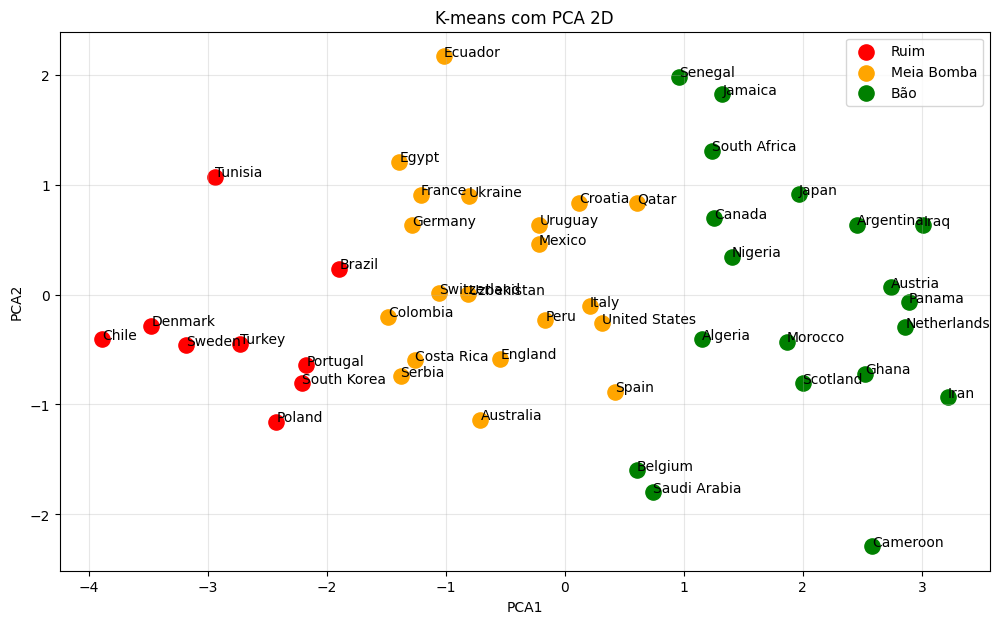

In [ ]:
#Plotar os graficos

plt.figure(figsize=(12,7))
for grupo, cor in cores.items():
  f = filtros[grupo]
  plt.scatter(pontos[f, 0], pontos[f, 1], s=120, color=cor, label=grupo)

for(x, y, _), time in zip(pontos, tabela.index):
  plt.annotate(time, (x, y))

plt.xlabel("PCA1")
plt.ylabel("PCA2")
plt.title(f"K-means com PCA 2D")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

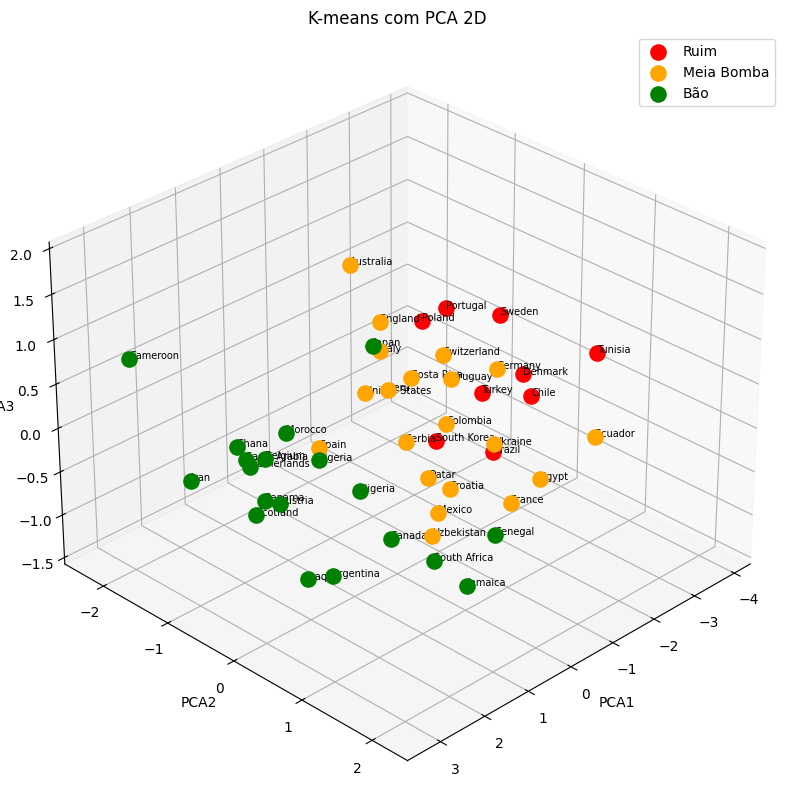

In [ ]:
fig = plt.figure(figsize=(13,10))
ax = fig.add_subplot(projection='3d')

for grupo, cor in cores.items():
  f = filtros[grupo]
  ax.scatter(pontos[f, 0], pontos[f, 1], pontos[f, 2], s=120, color=cor, label=grupo, depthshade=False)

for(x, y, z), time in zip(pontos, tabela.index):
  ax.text(x, y, z, time, fontsize=7)

ax.set_xlabel("PCA1")
ax.set_ylabel("PCA2")
ax.set_zlabel("PCA3")
ax.set_title(f"K-means com PCA 2D")
ax.view_init(elev=30, azim=45)
ax.legend()
plt.show()